# Lennard-Jones Clusters by Simulated Annealing

The **Lennard-Jones (LJ) potential** models how two neutral atoms, such as noble gases, interact. At short range they repel strongly because their electron clouds overlap (Pauli exclusion). At long range they attract weakly through induced dipoles (van der Waals forces). For two atoms a distance $r$ apart,
$$V(r) = 4\varepsilon\left[\left(\frac{\sigma}{r}\right)^{12} - \left(\frac{\sigma}{r}\right)^{6}\right],$$
where $\varepsilon$ is the well depth and $\sigma$ sets the length scale. The minimum lies at $r^* = 2^{1/6}\sigma$ with $V(r^*) = -\varepsilon$. We work in reduced units, $\varepsilon = \sigma = 1$.

**The problem:** for a cluster of $N$ atoms with total energy $E(\mathbf{r}_1,\dots,\mathbf{r}_N) = \sum_{i<j} V(r_{ij})$, find the $3N$ coordinates that give the *global* minimum. The answers are known for many sizes and make good checks. The dimer has $E=-1$, the triangle $-3$, the tetrahedron ($N=4$) $-6$, and the icosahedron ($N=13$) $-44.326801$. The Cambridge Cluster Database lists putative global minima for much larger $N$.

**Why there are so many local minima:** every pair of atoms wants to sit at the same distance $r^*$, but in 3D that is impossible once $N > 4$. The cluster is *frustrated* and has to compromise, and many very different arrangements compromise almost equally well. The number of these distinct packings grows combinatorially, so the number of local minima grows roughly exponentially with $N$. LJ$_{13}$ already has about 1500. A gradient-based optimizer slides into the nearest basin and stays there. Simulated annealing uses thermal fluctuations to hop over the barriers between basins, then cools slowly so the system settles into the deepest one.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Reduced units: energies in units of epsilon, lengths in units of sigma
epsilon = 1.0
sigma = 1.0

# Pair potential V(r)
def LennardJones(r, epsilon=epsilon, sigma=sigma):
    sr6 = (sigma / r) ** 6
    return 4 * epsilon * (sr6**2 - sr6)

# Total cluster energy, pos has shape (N, 3); each pair i<j counted once
def total_energy(pos):
    i, j = np.triu_indices(len(pos), k=1)
    r = np.linalg.norm(pos[i] - pos[j], axis=1)
    return LennardJones(r).sum()

# Energy and analytic gradient of a flattened (3N,) position vector, for fast quenches
def energy_and_grad(x):
    pos = x.reshape(-1, 3)
    i, j = np.triu_indices(len(pos), k=1)
    d = pos[i] - pos[j]
    r = np.linalg.norm(d, axis=1)
    sr6 = (sigma / r) ** 6
    f = (4 * epsilon * (6 * sr6 - 12 * sr6**2) / r**2)[:, None] * d   # (dV/dr) * d/r
    grad = np.zeros_like(pos)
    np.add.at(grad, i, f)
    np.add.at(grad, j, -f)
    return LennardJones(r).sum(), grad.ravel()

# Checks: pair minimum is -epsilon at r* = 2^(1/6) sigma, and a triangle with side r* has E = -3
r_star = 2 ** (1 / 6) * sigma
assert np.isclose(LennardJones(r_star), -epsilon)
triangle = r_star * np.array([[0, 0, 0], [1, 0, 0], [0.5, np.sqrt(3) / 2, 0]])
assert np.isclose(total_energy(triangle), -3 * epsilon)

# Check: analytic gradient matches a central finite difference on a random cluster
x0 = np.random.default_rng(1).uniform(-1.5, 1.5, size=3 * 6)
h = 1e-6
fd = [(total_energy((x0 + h * e).reshape(-1, 3)) - total_energy((x0 - h * e).reshape(-1, 3))) / (2 * h) for e in np.eye(x0.size)]
assert np.allclose(energy_and_grad(x0)[1], fd, rtol=1e-5, atol=1e-6)

In [2]:
import itertools
from scipy.optimize import minimize
from joblib import Parallel, delayed

# Simulated annealing parameters (temperature in units of epsilon / k_B)
initial_temp = 0.4      # above LJ13 melting (~0.3), so atoms rearrange freely; much higher and they evaporate
final_temp = 0.01       # cold enough that the cluster is frozen into one basin
iters_per_atom = 7500   # n_iter = 7500 N single-atom moves, ~10^5 for LJ13
step_size = 0.1         # max displacement per move, in sigma

# Slide downhill to the bottom of the current basin (the nearest local minimum)
def quench(pos):
    res = minimize(energy_and_grad, pos.ravel(), jac=True, method="L-BFGS-B", options=dict(ftol=1e-15, gtol=1e-8))
    return res.x.reshape(-1, 3), res.fun

# Interaction energy of atom a, placed at x, with all the other atoms
def atom_energy(pos, a, x):
    r = np.linalg.norm(pos - x, axis=1)
    r[a] = np.inf   # no self-interaction, V(inf) = 0
    return LennardJones(r).sum()

def simulated_annealing(N, seed=0, quench_every=1000):
    rng = np.random.default_rng(seed)
    n_iter = iters_per_atom * N
    cooling_rate = (final_temp / initial_temp) ** (1 / n_iter)  # geometric: T reaches final_temp at the last step

    # Start on a cubic lattice with spacing r_star, so no two atoms overlap
    k = int(np.ceil(N ** (1 / 3)))
    pos = r_star * np.array(list(itertools.product(range(k), repeat=3))[:N], dtype=float)
    pos -= pos.mean(axis=0)
    R_box = r_star * N ** (1 / 3)  # confining sphere, stops atoms evaporating at high T

    E_cur = total_energy(pos)
    best_pos, best_E = pos.copy(), E_cur
    local_minima = set()  # distinct basin energies visited
    history = []          # (T, E) for plotting
    T = initial_temp

    for step in range(n_iter):
        # Propose moving one random atom; only its own pair energies change
        a = rng.integers(N)
        new = pos[a] + rng.uniform(-step_size, step_size, size=3)

        # Metropolis: always accept downhill, accept uphill with probability exp(-dE/T)
        if np.linalg.norm(new) < R_box:
            dE = atom_energy(pos, a, new) - atom_energy(pos, a, pos[a])
            if dE < 0 or rng.random() < np.exp(-dE / T):
                pos[a] = new
                E_cur += dE

        # Keep the lowest energy found so far
        if E_cur < best_E:
            best_pos, best_E = pos.copy(), E_cur

        # Quench the current state to see which local minimum it belongs to
        if step % quench_every == 0:
            local_minima.add(round(quench(pos)[1], 4))

        history.append((T, E_cur))
        T *= cooling_rate

    # Check: the running sum of dE agrees with a full recompute
    assert np.isclose(E_cur, total_energy(pos))

    # SA ends slightly above the basin floor at finite T, so quench the best state to the exact minimum
    best_pos, best_E = quench(best_pos)
    return best_pos, best_E, local_minima, np.array(history)

# Run independent annealing jobs [(N, seed), ...] in parallel on all CPU cores
def run_sa(jobs):
    return Parallel(n_jobs=-1)(delayed(simulated_annealing)(N, seed) for N, seed in jobs)

## Our setup

**Annealing.** We start the $N$ atoms on a small cubic grid with spacing $r^*$ and keep them inside a sphere of radius $r^* N^{1/3}$, so they cannot drift apart while hot. Each step moves one random atom by up to $0.1\sigma$. The move is accepted by the Metropolis rule: always if the energy drops, and with probability $e^{-\Delta E/T}$ if it rises. The temperature falls geometrically from $T=0.4$ (just above where LJ$_{13}$ melts) to $T=0.01$ over $7500N$ steps, about $10^5$ for LJ$_{13}$, so larger clusters get proportionally more moves. At the end we let the best configuration slide straight downhill to the exact bottom of its basin (a *quench*), since at finite $T$ the cluster sits slightly above it.

**Counting minima.** Annealing deliberately ignores most minima, so it cannot count them. Instead we drop the atoms at random positions many times and quench each one. The number of distinct final energies estimates how many minima exist. Before counting a result, we make sure it is a true minimum: a small random kick followed by another quench escapes saddle points, and we keep only converged quenches where the cluster is still in one piece. For small $N$ this census finds every minimum. For larger $N$ the rarest ones are missed, so the counts there are lower bounds.

**Speed.** Independent annealing runs and chunks of random starts run in parallel on all CPU cores with `joblib`.

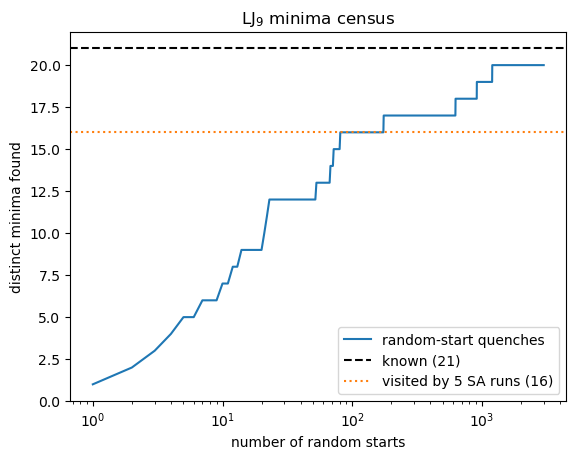

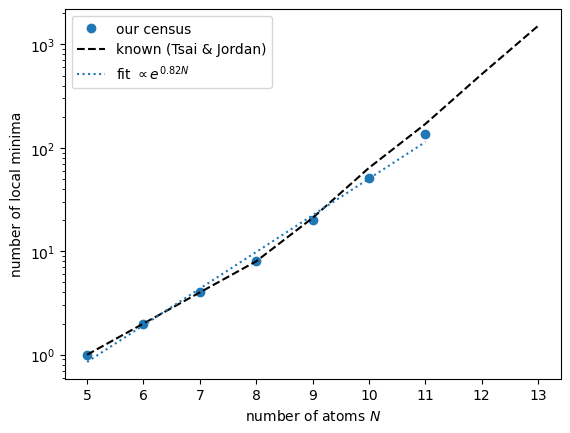

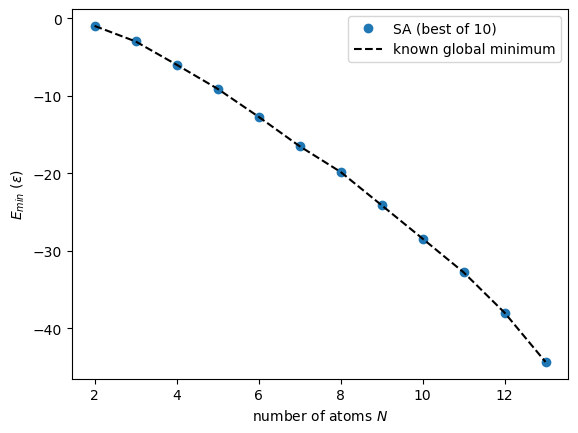

N= 2  SA   -1.000000  known   -1.000000  ok
N= 3  SA   -3.000000  known   -3.000000  ok
N= 4  SA   -6.000000  known   -6.000000  ok
N= 5  SA   -9.103852  known   -9.103852  ok
N= 6  SA  -12.712062  known  -12.712062  ok
N= 7  SA  -16.505384  known  -16.505384  ok
N= 8  SA  -19.821489  known  -19.821489  ok
N= 9  SA  -24.113360  known  -24.113360  ok
N=10  SA  -28.422532  known  -28.422532  ok
N=11  SA  -32.765970  known  -32.765970  ok
N=12  SA  -37.967600  known  -37.967600  ok
N=13  SA  -44.326801  known  -44.326801  ok


In [3]:
from scipy.sparse.csgraph import connected_components

# Known results: global minima from the Cambridge Cluster Database, minima counts from Tsai & Jordan (1993)
known_E = {2: -1.0, 3: -3.0, 4: -6.0, 5: -9.103852, 6: -12.712062, 7: -16.505384, 8: -19.821489,
           9: -24.113360, 10: -28.422532, 11: -32.765970, 12: -37.967600, 13: -44.326801}
known_count = {5: 1, 6: 2, 7: 4, 8: 8, 9: 21, 10: 64, 11: 170, 12: 515, 13: 1509}

# Energies of the minima reached from n_starts random starts (nan if the quench is rejected)
def quench_random_starts(N, n_starts, seed):
    rng = np.random.default_rng(seed)
    energies = []
    for _ in range(n_starts):
        x = rng.uniform(-1, 1, size=3 * N) * 0.8 * r_star * N ** (1 / 3)
        for _ in range(3):  # quench, kick, quench again: kicks push it off saddle points
            res = minimize(energy_and_grad, x, jac=True, method="L-BFGS-B", options=dict(ftol=1e-15, gtol=1e-8))
            x = res.x + rng.normal(0, 0.02, size=x.size)
        pos = res.x.reshape(-1, 3)
        one_piece = connected_components(np.linalg.norm(pos[:, None] - pos[None], axis=2) < 1.5 * sigma)[0] == 1
        energies.append(round(res.fun, 3) if np.linalg.norm(res.jac) < 1e-5 and one_piece else np.nan)
    return energies

# Running count of distinct minima, in the order the starts were made
def running_count(energies):
    found, running = set(), []
    for E in energies:
        if not np.isnan(E):
            found.add(E)
        running.append(len(found))
    return running

# Split each N's 3000 starts into 10 chunks and run all chunks in parallel
Ns = range(5, 12)
n_starts, n_chunks = 3000, 10
jobs = [(N, s) for N in Ns for s in range(n_chunks)]
chunks = Parallel(n_jobs=-1)(delayed(quench_random_starts)(N, n_starts // n_chunks, s) for N, s in jobs)
counts = {N: running_count(np.concatenate([e for (n, _), e in zip(jobs, chunks) if n == N])) for N in Ns}

def local_minima_plot(N=9):
    # Census at fixed N: does the count saturate at the known value? Compare to what annealing visits.
    sa_minima = set().union(*(run[2] for run in run_sa([(N, s) for s in range(5)])))
    plt.plot(np.arange(1, len(counts[N]) + 1), counts[N], label="random-start quenches")
    plt.axhline(known_count[N], ls="--", c="k", label=f"known ({known_count[N]})")
    plt.axhline(len(sa_minima), ls=":", c="C1", label=f"visited by 5 SA runs ({len(sa_minima)})")
    plt.xscale("log"); plt.xlabel("number of random starts"); plt.ylabel("distinct minima found")
    plt.title(f"LJ$_{{{N}}}$ minima census"); plt.legend(); plt.show()

def local_minima_growth_plot():
    # Exponential growth shows up as a straight line on a log axis
    n = np.array([counts[N][-1] for N in Ns])
    b, a = np.polyfit(list(Ns), np.log(n), 1)
    plt.semilogy(list(Ns), n, "o", label="our census")
    plt.semilogy(list(known_count), list(known_count.values()), "k--", label="known (Tsai & Jordan)")
    plt.semilogy(list(Ns), np.exp(a + b * np.array(list(Ns))), "C0:", label=f"fit $\\propto e^{{{b:.2f}N}}$")
    plt.xlabel("number of atoms $N$"); plt.ylabel("number of local minima"); plt.legend(); plt.show()

def energy_per_minima(n_seeds=10):  # one LJ13 run finds the icosahedron ~45% of the time
    # Best-of-n_seeds annealing energy vs the known global minimum for each N
    N_list = list(known_E)
    runs = run_sa([(N, s) for N in N_list for s in range(n_seeds)])
    best = [min(runs[k * n_seeds:(k + 1) * n_seeds], key=lambda run: run[1]) for k in range(len(N_list))]
    E_sa = [run[1] for run in best]
    plt.plot(N_list, E_sa, "o", label=f"SA (best of {n_seeds})")
    plt.plot(N_list, list(known_E.values()), "k--", label="known global minimum")
    plt.xlabel("number of atoms $N$"); plt.ylabel("$E_{min}$ ($\\varepsilon$)"); plt.legend(); plt.show()
    for N, E in zip(N_list, E_sa):
        print(f"N={N:2d}  SA {E:11.6f}  known {known_E[N]:11.6f}  {'ok' if np.isclose(E, known_E[N], atol=1e-4) else 'MISSED'}")
    return {N: run[0] for N, run in zip(N_list, best)}  # best positions, for the 3D plots

local_minima_plot()
local_minima_growth_plot()
best_pos = energy_per_minima()

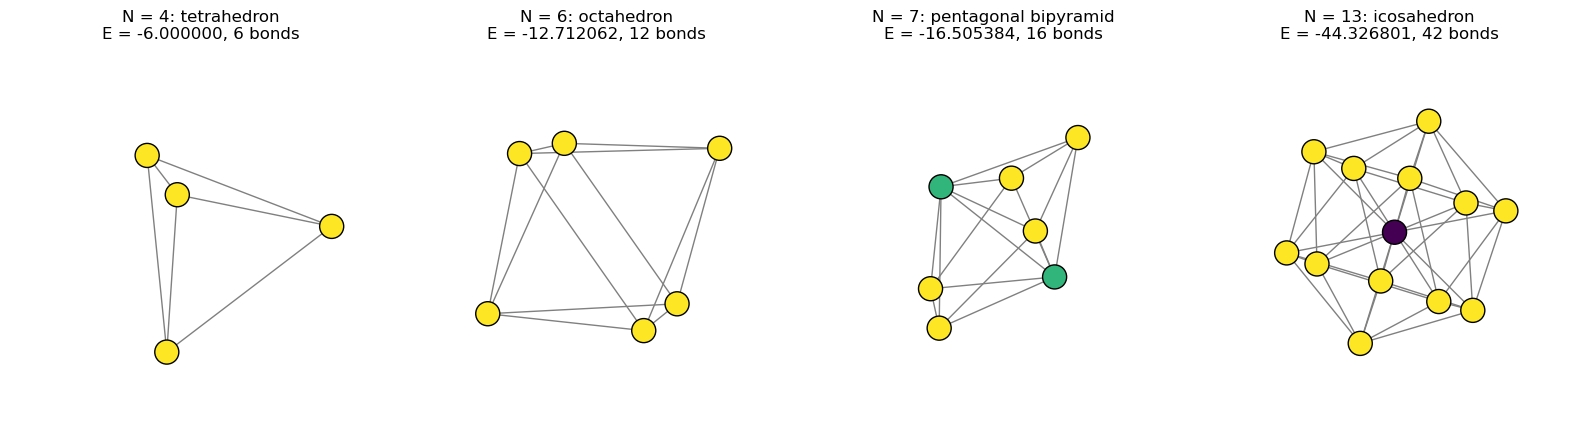

In [4]:
# 3D plots of configurations!
# Expected nearest-neighbour bond counts: tetrahedron 6, octahedron 12, pentagonal bipyramid 16 (apexes touch), icosahedron 42
shapes = {4: "tetrahedron", 5: "trigonal bipyramid", 6: "octahedron", 7: "pentagonal bipyramid", 13: "icosahedron"}

def three_dim_config(Ns=(4, 6, 7, 13)):
    fig = plt.figure(figsize=(4 * len(Ns), 4.5))
    for k, N in enumerate(Ns):
        pos = best_pos[N] - best_pos[N].mean(axis=0)
        ax = fig.add_subplot(1, len(Ns), k + 1, projection="3d")
        # Bonds: nearest neighbours sit near r*, the next shell is further than 1.3 r*
        i, j = np.triu_indices(N, k=1)
        bonded = np.linalg.norm(pos[i] - pos[j], axis=1) < 1.3 * r_star
        for a, b in zip(i[bonded], j[bonded]):
            ax.plot(*pos[[a, b]].T, c="gray", lw=1)
        # Colour by distance from the centre, so inner atoms (e.g. the LJ13 core) stand out
        lim = np.abs(pos).max()
        ax.scatter(*pos.T, s=300, c=np.linalg.norm(pos, axis=1), cmap="viridis", vmin=0, vmax=lim, edgecolors="k", alpha=1)
        ax.set(xlim=(-lim, lim), ylim=(-lim, lim), zlim=(-lim, lim)); ax.set_box_aspect((1, 1, 1)); ax.set_axis_off()
        ax.set_title(f"N = {N}: {shapes.get(N, '')}\nE = {total_energy(pos):.6f}, {bonded.sum()} bonds")
    plt.tight_layout(); plt.show()

three_dim_config()

Push harder idea:

Estimating the time efficiency for this algorithm:
Intuitively, for large N, we know the problem grows in complexity, but there is a known pattern that for very large N, that the atoms configure themselves in the HCP (Hexagonal Close Packed) lattice, which is one of the most efficient ways to pack things in 3D space. It is tied for efficiency with the FCC (Face Centered Cubic) lattice.

Let us see if we can reach such results. 

In [5]:
# Time_Efficiency of algorithm
# Expected time to find the global minimum = (time per run) / (chance a run succeeds) / (number of cores).
# We measure both factors for N = 7..20, fit how they grow, and extrapolate.
import os, time

# Known global minima for N = 14..20 (Cambridge Cluster Database)
known_E.update({14: -47.845157, 15: -52.322627, 16: -56.815742, 17: -61.317995,
                18: -66.530949, 19: -72.659782, 20: -77.177043})

# One annealing run, returning only its energy and wall time (cheaper to send back than the history)
def timed_sa(N, seed):
    t0 = time.perf_counter()
    E = simulated_annealing(N, seed)[1]
    return E, time.perf_counter() - t0

N_fit = np.arange(7, 21)
n_seeds = 30
n_cores = os.cpu_count()
# Interleave N in the job order, so every N runs under the same CPU load and t(N) is a fair comparison
out = Parallel(n_jobs=-1)(delayed(timed_sa)(N, s) for s in range(n_seeds) for N in N_fit)
E, t = np.array(out).T.reshape(2, n_seeds, len(N_fit)).transpose(0, 2, 1)   # -> (2, N, seed)
p = np.isclose(E, [[known_E[N]] for N in N_fit], atol=1e-4).mean(axis=1)   # success rate per run
t_run = t.mean(axis=1)                                                     # seconds per run (all cores busy)
assert (p > 0).all(), "some N never found its global minimum: raise n_seeds"

# Fits: success rate decays exponentially, p = e^(a + bN); run time is a power law, t = c N^d
b, a = np.polyfit(N_fit, np.log(p), 1)
d, log_c = np.polyfit(np.log(N_fit), np.log(t_run), 1)

def wall_time(N):  # expected seconds on this machine, independent restarts on all cores
    return np.exp(log_c) * N**d / np.exp(a + b * N) / n_cores

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.semilogy(N_fit, p, "o", label=f"measured ({n_seeds} runs each)")
ax1.semilogy(N_fit, np.exp(a + b * N_fit), ":", label=f"fit $\\propto e^{{{b:.3f}N}}$")
ax1.set(xlabel="number of atoms $N$", ylabel="success rate per SA run"); ax1.legend()

N_ext = np.arange(7, 151)
ax2.semilogy(N_ext, wall_time(N_ext), label=f"extrapolation, run time $\\propto N^{{{d:.2f}}}$")
ax2.semilogy(N_fit, t_run / p / n_cores, "o", label="measured")
for secs, name in [(60, "minute"), (3600, "hour"), (86400, "day"), (3.15e7, "year"), (4.35e17, "age of universe")]:
    ax2.axhline(secs, c="gray", lw=0.6); ax2.text(8, secs * 1.3, name, color="gray", fontsize=8)
ax2.set(xlabel="number of atoms $N$", ylabel=f"expected time on {n_cores} cores (s)"); ax2.legend(loc="lower right")
plt.tight_layout(); plt.show()

for N in [13, 38, 55, 100, 147, 1000]:
    print(f"N = {N:4d}:  {wall_time(N):9.2e} s  = {wall_time(N) / 3.15e7:9.2e} years")

KeyboardInterrupt: 

## Time estimation results

The expected time to find the global minimum is $t_\text{run}(N)\,/\,p(N)\,/\,n_\text{cores}$. Here $p(N)$ is the chance that one annealing run succeeds and $t_\text{run}(N)$ is the time for one run. Both are measured from 30 runs for each $N = 7$–$20$ and then extrapolated.

- **The success rate decays exponentially,** $p \propto e^{-0.164N}$. Each extra atom costs about 15% of the success chance, from about 85% at $N=7$ to 7–17% at $N=17$–$20$.
- **The time per run grows only as a power law,** $t_\text{run} \propto N^{1.16}$, so the exponential decay of $p$ dominates.

| $N$ | 13 | 38 | 55 | 100 | 147 | 1000 |
|---|---|---|---|---|---|---|
| expected time (10 cores) | ~1.5 s | ~5 min | ~2 h | ~10 months | ~3000 years | ~$10^{65}$ years |

**Caveats.** With 30 runs per $N$ the fitted exponent is only good to about ±30%, so read large-$N$ values as orders of magnitude. Some sizes are much harder than the trend because their global minimum has a different structure from their neighbours: $N=38$ (an FCC truncated octahedron), $75$–$77$ and $98$–$104$. The estimate also assumes our fixed schedule of $7500N$ steps; cooling more slowly would raise $p$ at the cost of longer runs.

**Conclusion.** Bulk-like FCC/HCP packing is expected only at around $10^5$ atoms, and LJ clusters stay icosahedral up to about $10^3$. Annealing already needs ~$10^{65}$ years at $N=1000$, so it cannot reach the crystal regime by brute force. That takes methods that exploit known structure, such as basin hopping or lattice-based searches.